# Observing conditions at SOAR

**What this notebook shows.** `kino.observing` answers, for a target and a night, *what the atmosphere and the moon are doing*: when the target is up, at what airmass, how bright the moon-lit sky is, how much light the atmosphere removes, and what seeing to expect at the observed wavelength. It knows nothing about instruments; its outputs feed the instrument backends (`kino.instruments`) and the forecast (`notebooks/10_sifs_forecast.ipynb`).

Every model here is either standard geometry (`astropy`) or a published relation, and each is cross-checked in the test suite. Where a number comes from a paper, the paper is named next to it.

| Piece | Source |
|---|---|
| SOAR position (lat $-30^\circ14'16.41''$, lon $-70^\circ44'01.11''$, ellipsoidal height 2738 m) | Mamajek (2013), [arXiv:1210.1616](https://arxiv.org/abs/1210.1616), Table 6 |
| Airmass $X(h)$ | Kasten & Young (1989), Appl. Opt. 28, 4735 |
| Seeing scaling $\mathrm{FWHM}\propto X^{3/5}\lambda^{-1/5}$ | Kolmogorov turbulence (Fried parameter $r_0\propto\lambda^{6/5}X^{-3/5}$) |
| Extinction curve | CTIO mean: Stone & Baldwin (1983) [MNRAS 204, 347]; Baldwin & Stone (1984) [MNRAS 206, 241] |
| Moonlit V-band sky | Krisciunas & Schaefer (1991), PASP 103, 1033 |

In [1]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import ICRS, TETE, SkyCoord
from astropy.time import Time
from kino_style import AQUA, BLUE, INK2, ORANGE, SEQ_BLUES, YELLOW

from kino.observing import (
    SOAR,
    atmospheric_transmission,
    extinction_coefficient,
    moon_state,
    night_window,
    seeing_at,
    sky_brightness_v,
    target_track,
)

print(f"SOAR: lat {SOAR.latitude:.4f}, lon {SOAR.longitude:.4f}, height {SOAR.location.height:.0f}")

SOAR: lat -30.2379 deg, lon -70.7336 deg, height 2738 m


## 1. The dark window of a night

A "night" is the evening that *begins* on a calendar date, found from the site's mean solar noon (no timezone handling, so it straddles a UT date change). The dark window is the stretch with the Sun below $-18^\circ$ (astronomical twilight).

At $30^\circ$ S the astronomical night is more than twice as long in southern winter as at the summer solstice. Since a forecast is only as good as the hours it can use, the first thing a proposal needs is *how many dark hours there are* in the semester.

shortest 6.6 h, longest 10.9 h


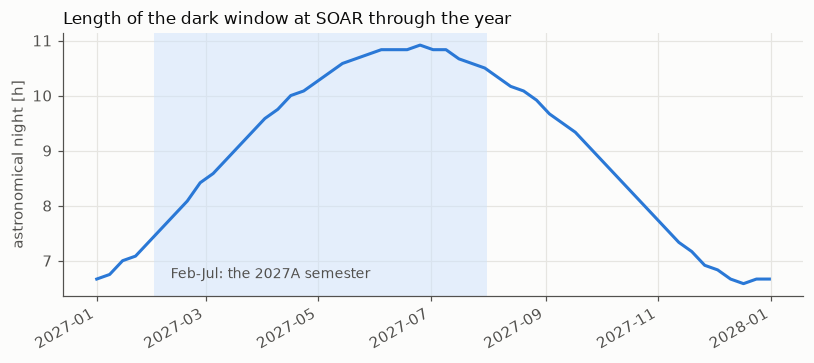

In [2]:
dates = Time("2027-01-01") + np.arange(0, 365, 7) * u.day
hours = np.array([night_window(SOAR, d.iso[:10]).duration.to_value(u.hour) for d in dates])

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(dates.datetime, hours, color=BLUE)
ax.axvspan(
    Time("2027-02-01").datetime, Time("2027-07-31").datetime, color=SEQ_BLUES[0], alpha=0.5, lw=0
)
ax.text(
    Time("2027-02-10").datetime,
    hours.min() + 0.1,
    "Feb-Jul: the 2027A semester",
    color=INK2,
    fontsize=9,
)
ax.set_ylabel("astronomical night [h]")
ax.set_title("Length of the dark window at SOAR through the year")
fig.autofmt_xdate()
fig.tight_layout()
print(f"shortest {hours.min():.1f} h, longest {hours.max():.1f} h")

## 2. Where a target is: altitude, airmass, parallactic angle

`target_track` gives altitude, Kasten-Young airmass and the parallactic angle at each time. The parallactic angle matters for slits: at high airmass the atmosphere disperses light along the parallactic direction, and a slit not aligned with it loses flux (Goodman has an atmospheric-dispersion corrector; SIFS is a fibre IFU, so it does not care about orientation).

Below: three targets that transit at local midnight, at declinations $-60^\circ$, $-25^\circ$ and $+5^\circ$. The horizontal line is the airmass 2 limit that the moonlight model and the forecast use.

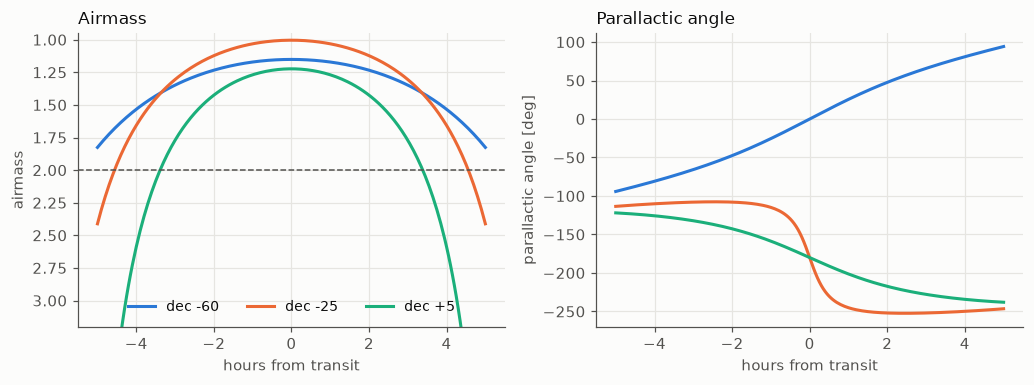

In [3]:
night = night_window(SOAR, "2026-10-03")
mid = night.times[len(night.times) // 2]
lst = mid.sidereal_time("apparent", longitude=SOAR.longitude)
times = mid + np.linspace(-5, 5, 201) * u.hour

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.6))
for dec, c in zip([-60, -25, 5], [BLUE, ORANGE, AQUA], strict=False):
    coord = SkyCoord(ra=lst, dec=dec * u.deg, frame=TETE(obstime=mid)).transform_to(ICRS())
    tr = target_track(SOAR, coord, times)
    x = np.where(np.isfinite(tr.airmass), tr.airmass, np.nan)
    hrs = (times - mid).to_value(u.hour)
    a1.plot(hrs, x, color=c, label=f"dec {dec:+d}")
    q = np.degrees(np.unwrap(np.radians(tr.parallactic_angle.to_value(u.deg))))
    a2.plot(hrs, q, color=c)
a1.axhline(2.0, color=INK2, lw=1, ls="--")
a1.legend(loc="lower center", ncol=3)
a1.set_ylim(3.2, 0.95)
a1.set_xlabel("hours from transit")
a1.set_ylabel("airmass")
a1.set_title("Airmass")
a2.set_xlabel("hours from transit")
a2.set_ylabel("parallactic angle [deg]")
a2.set_title("Parallactic angle")
fig.tight_layout()

## 3. The moon

A moonlit sky is the dominant uncertainty in a dark-sky forecast. `moon_state` returns the illumination, the phase angle (0 at full), the altitude, and the *topocentric* separation from the target (lunar parallax is about $1^\circ$, so the geocentric separation would be wrong at the level that matters for scattered light).

The plot shows, for every night of the 2027A months, the moon's illumination at the middle of the night, and the fraction of the dark window in which the moon is below the horizon. The nights that are both dark *and* moon-free are the ones an IFU that is read-noise limited in the dark (as SIFS is, see notebook 09) can use to full advantage.

72 of 181 nights have <30% illumination
or the moon down for over 70% of the dark window


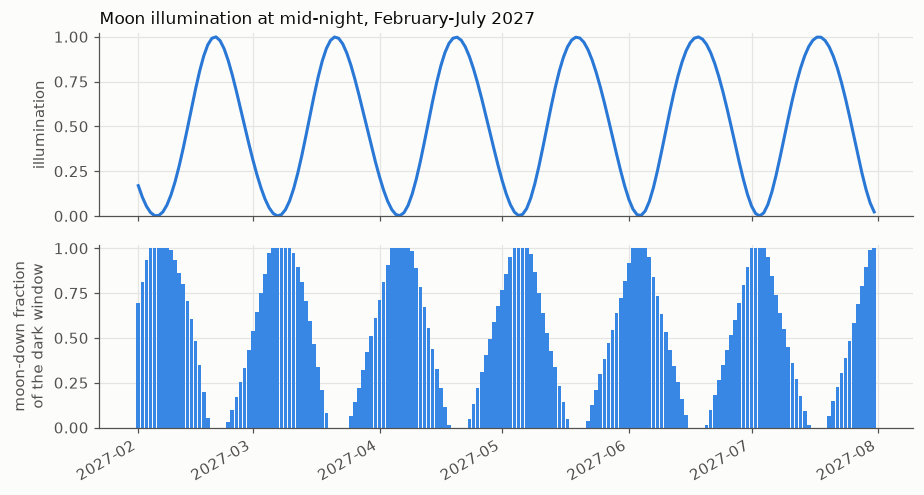

In [4]:
days = Time("2027-02-01") + np.arange(0, 181) * u.day
ill, moon_free = [], []
for d in days:
    n = night_window(SOAR, d.iso[:10])
    ms = moon_state(SOAR, n.times)
    ill.append(float(ms.illumination[len(n.times) // 2]))
    moon_free.append(float(np.mean(ms.altitude < 0 * u.deg)))
ill, moon_free = np.array(ill), np.array(moon_free)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8.5, 4.6), sharex=True)
a1.plot(days.datetime, ill, color=BLUE)
a1.set_ylabel("illumination")
a1.set_ylim(0, 1.02)
a1.set_title("Moon illumination at mid-night, February-July 2027")
a2.bar(days.datetime, moon_free, width=0.9, color=SEQ_BLUES[3])
a2.set_ylabel("moon-down fraction\nof the dark window")
a2.set_ylim(0, 1.02)
fig.autofmt_xdate()
fig.tight_layout()
good = (ill < 0.3) | (moon_free > 0.7)
print(f"{good.sum()} of {len(days)} nights have <30% illumination")
print("or the moon down for over 70% of the dark window")

## 4. Seeing depends on airmass and wavelength

Site seeing is quoted at 500 nm at zenith. What reaches the detector is different: Kolmogorov turbulence gives a Fried parameter $r_0\propto\lambda^{6/5}X^{-3/5}$, so

$$\mathrm{FWHM}(\lambda, X)=\mathrm{FWHM}_{500}\;X^{3/5}\left(\frac{\lambda}{500\ \mathrm{nm}}\right)^{-1/5}.$$

This is an approximation (it ignores the finite outer scale, which shrinks the FWHM further in the red, and dome seeing), so it *shapes* a curve rather than predicting one image. The forecast uses it to turn "the seeing is 0.9 arcsec" into what the instrument's PSF should be at the observed line and at each moment's airmass.

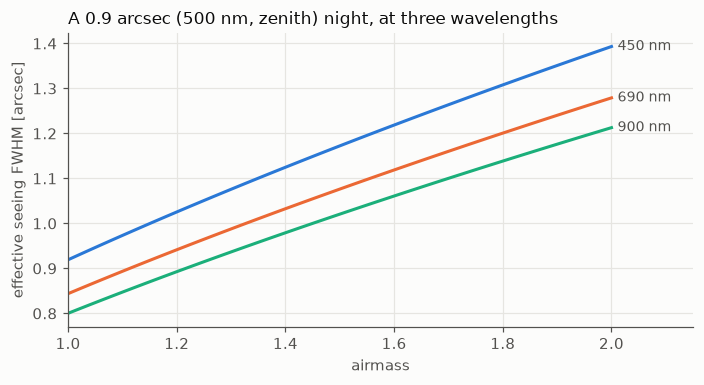

In [5]:
X = np.linspace(1.0, 2.0, 50)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for wl, c in [(450, BLUE), (690, ORANGE), (900, AQUA)]:
    s = seeing_at(0.9 * u.arcsec, X, wl * u.nm)
    ax.plot(X, s.value, color=c)
    ax.annotate(
        f"{wl} nm",
        (X[-1], s.value[-1]),
        xytext=(4, 0),
        textcoords="offset points",
        color=INK2,
        fontsize=9,
        va="center",
    )
ax.set_xlim(1.0, 2.15)
ax.set_xlabel("airmass")
ax.set_ylabel("effective seeing FWHM [arcsec]")
ax.set_title("A 0.9 arcsec (500 nm, zenith) night, at three wavelengths")
fig.tight_layout()

## 5. How much light the atmosphere removes

The CTIO mean extinction curve (mag per airmass) is steep in the blue and nearly flat in the red; the transmission of a source at airmass $X$ is $10^{-0.4kX}$. It is a mean from Tololo (about 10 km from Pachon) and does not follow night-to-night aerosol changes or cloud.

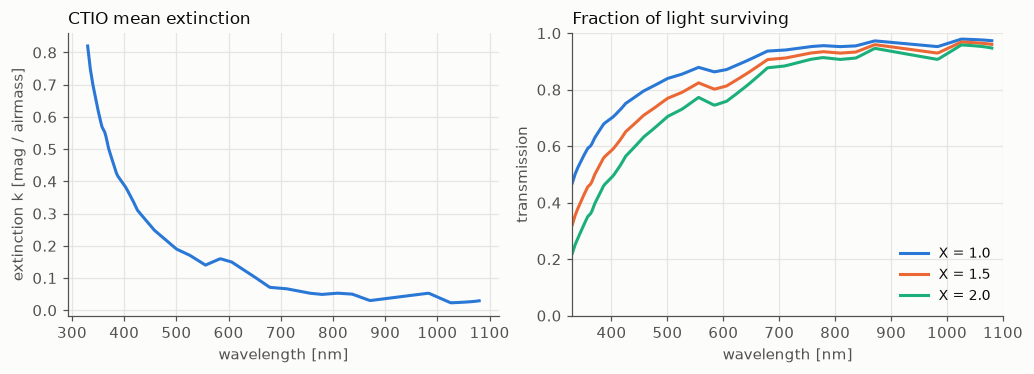

In [6]:
wl = np.linspace(3300, 10800, 300) * u.AA
k = extinction_coefficient(wl)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.5))
a1.plot(wl.value / 10, k, color=BLUE)
a1.set_xlabel("wavelength [nm]")
a1.set_ylabel("extinction k [mag / airmass]")
a1.set_title("CTIO mean extinction")
for X_, c in [(1.0, BLUE), (1.5, ORANGE), (2.0, AQUA)]:
    a2.plot(wl.value / 10, atmospheric_transmission(wl, X_), color=c, label=f"X = {X_}")
a2.legend(loc="lower right")
a2.set_xlim(330, 1100)
a2.set_ylim(0, 1)
a2.set_xlabel("wavelength [nm]")
a2.set_ylabel("transmission")
a2.set_title("Fraction of light surviving")
fig.tight_layout()

## 6. The moonlit sky in the V band (Krisciunas & Schaefer 1991)

The classic empirical model for scattered moonlight,

$$B_\mathrm{moon}=f(\rho)\,I^*\,10^{-0.4kX(Z_m)}\left[1-10^{-0.4kX(Z)}\right],\qquad I^*=10^{-0.4(3.84+0.026|\alpha|+4\times10^{-9}\alpha^4)},$$

$$f(\rho)=10^{5.36}\left[1.06+\cos^2\rho\right]+10^{6.15-\rho/40},$$

with $\alpha$ the lunar phase angle, $\rho$ the moon-target separation, $Z_m$ and $Z$ the moon and target zenith distances and $k$ the V extinction. It is quoted as accurate to 8-23 %. Here it sits on the CTIO dark-sky mean $V=21.79\pm0.22$ (Krisciunas et al. 2007, Table 6).

The dashed lines are Gemini South's published optical sky-background bins (a "dark" 50th percentile of $V=20.7$, "grey" $19.5$, "bright" $18.0$): Gemini South is about 400 m from SOAR. A quarter moon lands on "dark", a full moon a few tenths above "bright".

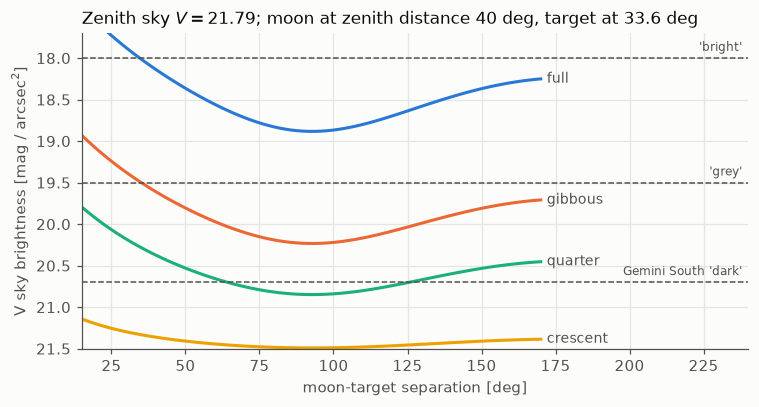

In [7]:
k_v = float(extinction_coefficient(5556 * u.AA)[0])
rho = np.linspace(15, 170, 80) * u.deg
fig, ax = plt.subplots(figsize=(7.0, 3.8))
for alpha, c, name in [
    (0, BLUE, "full"),
    (60, ORANGE, "gibbous"),
    (90, AQUA, "quarter"),
    (135, YELLOW, "crescent"),
]:
    r = sky_brightness_v(21.79, alpha * u.deg, rho, 40 * u.deg, 33.6 * u.deg, k_v)
    ax.plot(rho.value, r["total_mag"], color=c)
    ax.annotate(
        name,
        (rho.value[-1], r["total_mag"][-1]),
        xytext=(4, 0),
        textcoords="offset points",
        color=INK2,
        fontsize=9,
        va="center",
    )
for v, lab in [(20.7, "Gemini South 'dark'"), (19.5, "'grey'"), (18.0, "'bright'")]:
    ax.axhline(v, color=INK2, lw=1, ls="--")
    ax.text(238, v - 0.05, lab, color=INK2, fontsize=8, va="bottom", ha="right")
ax.invert_yaxis()
ax.set_xlim(15, 240)
ax.set_ylim(21.5, 17.7)
ax.set_xlabel("moon-target separation [deg]")
ax.set_ylabel("V sky brightness [mag / arcsec$^2$]")
ax.set_title("Zenith sky $V=21.79$; moon at zenith distance 40 deg, target at 33.6 deg")
fig.tight_layout()

## What this layer does *not* do yet

* It is V band only here; the full wavelength-dependent sky (moonlight colour, airglow lines) is the next notebook.
* Extinction is a mean, not the night's. Cloud is not modelled.
* No Cerro Pachon-specific corrections (light pollution from La Serena, aerosols).